In [1]:
from Outsu_funs import *

# Import data

In [4]:
df = pd.read_csv("./data.csv",  sep=",", encoding="cp1252")

In [38]:
df = df[df["area"] > 30]
df.shape

(104, 15)

In [39]:
# Features for classification
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "circularity",
]

In [40]:
# Clean class labels
df["Class"] = (
    df["Class"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert features to numeric
for feature in features:
    df[feature] = pd.to_numeric(
        df[feature],
        errors="coerce"
    )

# Manually labeled objects
labeled = df[
    df["Class"].isin(["foci", "aggregate"])
].dropna(subset=features).copy()

print("Training samples:")
print(labeled["Class"].value_counts())

Training samples:
Class
aggregate    84
foci         17
Name: count, dtype: Int64


# PCA

In [41]:
# Select objects with known classes and complete features
pca_df = df.dropna(subset=features + ["Class"]).copy()

# Select features and scale them 
X = pca_df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

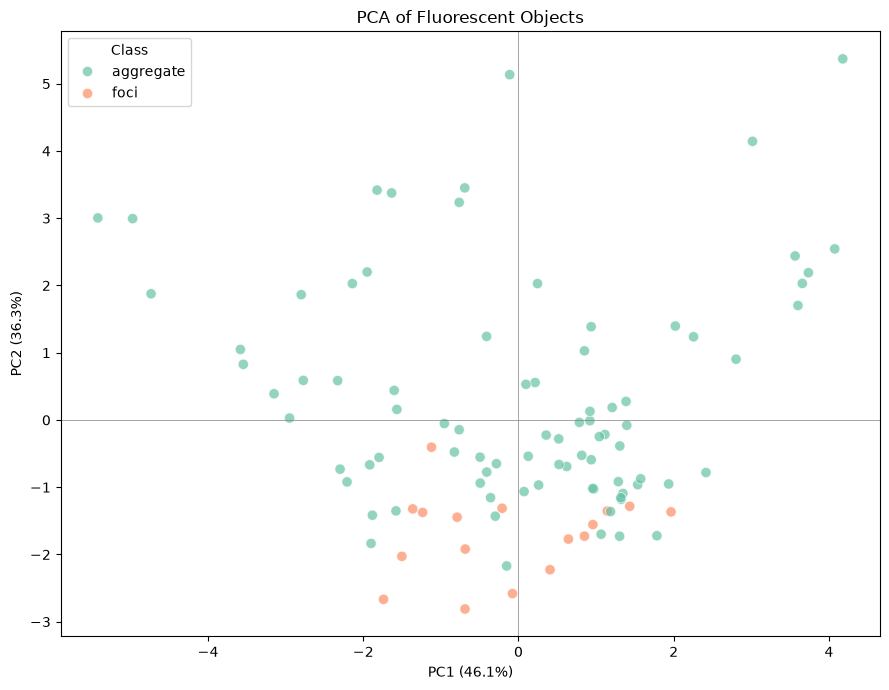

In [42]:
pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Class",
    palette="Set2",
    s=55,
    alpha=0.7
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of Fluorescent Objects")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)

plt.tight_layout()
plt.show()

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.patches import Ellipse
from scipy.stats import chi2


def plot_kmeans_ellipses(
    pca_df,
    features=("PC1", "PC2"),
    n_clusters=2,
    confidence=0.95,
    figsize=(9, 7),
    random_state=42
):
    # Prepare data
    df = pca_df.copy()
    X = df[list(features)].dropna()

    # K-means clustering
    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=random_state,
        n_init=20
    )

    clusters = kmeans.fit_predict(X)
    df["Cluster"] = pd.Series(clusters, index=X.index)

    # K-means centroids
    centroids = kmeans.cluster_centers_

    # Silhouette score
    score = silhouette_score(X, clusters)

    fig, ax = plt.subplots(figsize=figsize)
    colors = plt.cm.tab10.colors

    # Scale for covariance-based data ellipse
    scale = chi2.ppf(confidence, df=2)

    for cluster in range(n_clusters):

        points = X.iloc[np.where(clusters == cluster)[0]].to_numpy()
        n = len(points)
        color = colors[cluster % len(colors)]

        # Plot observations
        ax.scatter(
            points[:, 0],
            points[:, 1],
            color=color,
            alpha=0.4,
            s=35,
            label=f"Cluster {cluster} (n={n})"
        )

        # Plot centroid
        centroid = centroids[cluster]

        ax.scatter(
            centroid[0],
            centroid[1],
            color=color,
            marker="X",
            s=250,
            edgecolor="black",
            linewidth=1.2,
            zorder=5
        )

        # Calculate covariance ellipse
        if n >= 3:
            cov = np.cov(points, rowvar=False)

            eigenvalues, eigenvectors = np.linalg.eigh(cov)

            order = np.argsort(eigenvalues)[::-1]
            eigenvalues = eigenvalues[order]
            eigenvectors = eigenvectors[:, order]

            width, height = (
                2 * np.sqrt(np.maximum(eigenvalues, 0) * scale)
            )

            angle = np.degrees(
                np.arctan2(
                    eigenvectors[1, 0],
                    eigenvectors[0, 0]
                )
            )

            ellipse = Ellipse(
                xy=centroid,
                width=width,
                height=height,
                angle=angle,
                edgecolor=color,
                facecolor=color,
                alpha=0.12
            )

            ax.add_patch(ellipse)

            border = Ellipse(
                xy=centroid,
                width=width,
                height=height,
                angle=angle,
                edgecolor=color,
                facecolor="none",
                linewidth=2
            )

            ax.add_patch(border)

    ax.axhline(0, color="gray", linestyle="--", alpha=0.3)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.3)

    ax.set_xlabel(features[0])
    ax.set_ylabel(features[1])

    ax.set_title(
        f"K-means — {n_clusters} Clusters "
        f"({confidence:.0%} Data Ellipses)\n"
        f"Silhouette score = {score:.3f}"
    )

    ax.legend(frameon=False)
    ax.grid(alpha=0.15)
    ax.set_aspect("equal", adjustable="datalim")

    plt.tight_layout()
    plt.show()

    return df, kmeans

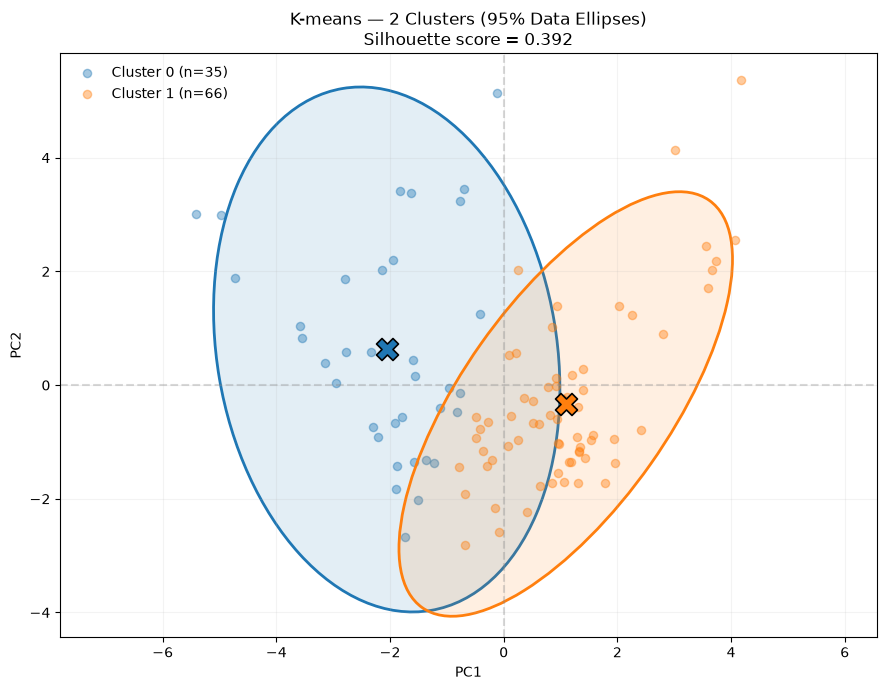

In [44]:
clustered_df, kmeans = plot_kmeans_ellipses(
    pca_df,
    n_clusters=2,
    confidence=0.95
)

In [45]:
from sklearn.metrics import silhouette_samples, silhouette_score

X = clustered_df[["PC1", "PC2"]]
labels = clustered_df["Cluster"]

# Overall score
score = silhouette_score(X, labels)

# Score for each object
clustered_df["silhouette"] = silhouette_samples(X, labels)

print("Overall silhouette score:", score)

print(
    clustered_df.groupby("Cluster")["silhouette"]
    .agg(["mean", "median", "min", "max"])
)

Overall silhouette score: 0.3916562974264816
             mean    median       min       max
Cluster                                        
0        0.284955  0.339612 -0.020190  0.500502
1        0.448240  0.505974  0.077316  0.612615


In [46]:
import numpy as np

centroids = kmeans.cluster_centers_

distance = np.linalg.norm(
    centroids[0] - centroids[1]
)

print("K-means centroid distance:", distance)

K-means centroid distance: 3.291976247733013


In [37]:
X = clustered_df[["PC1", "PC2"]].dropna().to_numpy()

total_ss = np.sum((X - X.mean(axis=0)) ** 2)

within_ss = kmeans.inertia_

r_squared = 1 - within_ss / total_ss

print("Cluster R²:", r_squared)

Cluster R²: 0.6110910993190419
